# Quiz 1 (25/09/02)

## Conditioning, stability, and coding practices

### 1. 
If the relative condition number of the real-valued functions $f$ and $g$ are $\kappa_f$ and $\kappa_g$ respectively, show that for $h(x) = f(g(x))$, 

$$\kappa_h(x) = \kappa_f(g(x))\kappa_g(x).$$

### 2.
The polynomial $p(x) = a_0 + a_1x + \ldots + a_nx^n$ has a root $x = r$. What is the (relative) condition number of the root $r$ with respect to perturbations in the coefficient $a_k$, keeping all other coefficients constant? Simplify your answer as much as possible. Deduce when root finding problems become ill-conditioned (there are multiple cases here!).

### 3.
Consider the machine algorithm (that uses floating-point representation) for subtracting $1$ from a real number. You'll investigate whether it's stable and backwards stable.
* a) The exact problem (a mapping $f: X \mapsto Y$) is $ f(x) = 1 - x. $
Write down in words the steps of the machine algorithm $\tilde{f}$ that computes the difference. Express $\tilde{f}(x)$ in terms of the input $x$.
* b) What does $\tilde{f}(x)$ have to equal, in terms of a floating-point number close to $x$ denoted $\tilde{x},$ for the algorithm to be _backwards stable_?
* c) By expressing $\tilde{x}$ in terms of $x$ and some small relative roundoff error $\varepsilon$ ($|\varepsilon| \leq \mu_M$), eliminate $\tilde{x}$ from the above result. To **first order** in small quantities, what does $\varepsilon$ have to equal for backwards stability? Is this $\varepsilon$ **always** $\mathcal{O}(\mu_M)$ (i.e. for all $x$, uniformly)? What does this mean for the backwards stability of this algorithm?
* d) What is the condition for _stability_ in terms of $f$, $\tilde{f}$, $x$, and $\tilde{x}$? 
* e) Is this algorithm stable? Show your work. 

### 4. 
Consider the code below. 
- a) Write an informative docstring for the function `chebD`. 

_Hint_: In the docstring, comment on the ordering of nodes stored in `x`. 

- b) Write a unit test for the same function. 

_Hints_: 
- The unit test should consider a known solution and test whether the function behaves as expected.
- It should have an `assert` statement at the end.
- The `assert` statement conventionally checks whether some expected error is below a reasonable bound.
- Make sure the unit test is actually passing!
- If considering an interval different from $[-1, 1]$, you'll have to scale $Df$ by $h/2$ (where $h$ is the length of the interval) to get $f'$. 

In [1]:
import numpy as np

In [2]:
def chebD(n):
    """
    A nice and informative docstring

    Parameters
    ----------

    Returns
    -------
    
    """
    if n == 0:
        x = 1; D = 0
    else:
        a = np.linspace(0.0, np.pi, n+1)
        x = np.cos(a)
        b = np.ones_like(x)
        b[0] = 2; b[-1] = 2
        d = np.ones_like(b)
        d[1::2] = -1
        c = b*d
        X = np.outer(x, np.ones(n+1))
        dX = X - X.T
        D = np.outer(c, 1/c) / (dX + np.identity(n+1))
        D = D - np.diag(D.sum(axis=1))
    return D, x

In [4]:
def test_chebD():
    # YOUR ANSWER HERE
    pass

### 5. 


This question takes you through an example where the condition number is not so easy to compute analytically.

Consider the initial value problem

\begin{align}
u'' + \lambda^2q(t) u &= 0, \quad t \in [t_i, t_f] = [-1, 1],\\
u(-1) &= 0, \\ 
u'(-1) &= \lambda, \\
\end{align}

with $q(t) = 1 - t^2\cos(3t)$, and $\lambda = 100$. 

- a) By perturbing the input parameter $t_f$ and inspecting the change in $u(t_f)$, compute an estimate of the relative condition number of the IVP with respect to this parameter. Use the code below to numerically solve the IVP (it calls `scipy`'s `solve_ivp`, you can check [its documentation](https://docs.scipy.org/doc/scipy/reference/generated/scipy.integrate.solve_ivp.html) for this exercise).
- b) Can you derive some sort of theoretical estimate for the condition number? Compare it to the numerical answer.

_Hints_:
- Think about what the solution looks like (you may plot it with `matplotlib`, see the code below). What's a rough estimate of a function that could approximate it? It's OK for this function to be a very crude approximation.
- Take this function, evaluate it at $t_f$, and use the definition of the relative condition number to derive your theoretical estimate.

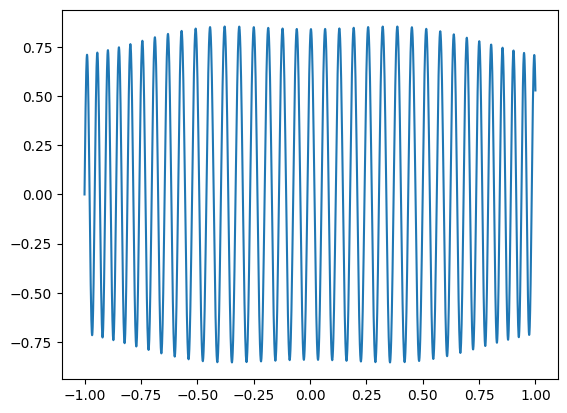

In [8]:
import scipy.integrate as sciintg
import matplotlib.pyplot as plt

# Solution interval
t0 = -1.0
tf1 = 1.0
t_span1 = (t0, tf1)

# Right-hand side of the ODE, written as a first-order system
l = 100.0
q = lambda t: 1 - t**2*np.cos(3*t)

def f(t, u):
    up = np.zeros_like(u)
    up[0] = u[1]
    up[1] = - l**2*q(t)*u[0]
    return up

# Initial conditions
y0 = np.array([0, l])

# Numerical solution -- set dense_output to False if not plotting.
solution1 = sciintg.solve_ivp(f, t_span1, y0, rtol = 1e-8, atol = 1e-8, dense_outpus = True)

# Plot of the solution
ts = solution1.t
us = solution1.y[0]
plt.plot(ts, us)

# YOUR ANSWER HERE